# 03 · Temperature is one line

**The question.** What does the temperature knob actually do?

**The claim.** Temperature divides the logits by a number before the softmax, and that is all it does. Below 1 it sharpens the distribution toward the top token; as T → 0 it *becomes* greedy, loops included. Above 1 it flattens the distribution toward uniform; as T → ∞ it samples every token equally, which is gibberish. In between is a band where text is both fluent and varied, and a sweep finds it.

**By the end** you will be able to predict what any temperature will do to a model's output, and why.

*Outputs:* `outputs/figures/03_*.png` and `outputs/results/03_*.json`.

In [1]:
import inspect
import textwrap

import pandas as pd
import torch

from src.config import get_settings

S = get_settings()
SEED = S.seed
pd.set_option("display.max_colwidth", 120)
pd.set_option("display.width", 160)
print(f"seed = {SEED}  (config/settings.yaml)")

from src.results import save_json
from src.visualisation import save_figure

seed = 42  (config/settings.yaml)


## 1. The whole implementation

In [2]:
from src.decoders import apply_temperature

print(inspect.getsource(apply_temperature))

def apply_temperature(logits: Tensor, temperature: float) -> Tensor:
    """Scale logits by ``1 / temperature``.

    Args:
        logits: ``(batch, vocab)`` scores. Not modified.
        temperature: ``T >= 0``. ``T == 0`` is the greedy limit and is special-cased *before*
            any division: every token except the argmax is masked to ``-inf``.

    Returns:
        ``(batch, vocab)`` warped logits.

    Raises:
        ValueError: if ``temperature`` is negative or not finite.
    """
    if not math.isfinite(temperature) or temperature < 0:
        raise ValueError(f"temperature must be a finite number >= 0, got {temperature}")
    if temperature == 0:
        keep = torch.zeros_like(logits, dtype=torch.bool)
        keep.scatter_(-1, logits.argmax(dim=-1, keepdim=True), True)
        return logits.masked_fill(~keep, NEG_INF)
    return logits / temperature



Strip the docstring and the input checks and one line is left: `return logits / temperature`. `T = 0` is special-cased as the greedy limit so nothing divides by zero.

## 2. Five tokens, five temperatures

In [3]:
toy = torch.tensor([[2.0, 1.0, 0.5, 0.0, -1.0]])
temps = [0.25, 0.5, 1.0, 2.0, 5.0]
toy_table = pd.DataFrame(
    {f"T={t:g}": torch.softmax(apply_temperature(toy, t), dim=-1)[0].numpy() for t in temps},
    index=pd.Index([f"token {i} (logit {v:g})" for i, v in enumerate(toy[0].tolist())], name="token"),
)
save_json("03_toy_temperature_table", toy_table)
toy_table.round(3)

,T=0.25,T=0.5,T=1,T=2,T=5
token,,,,,
token 0 (logit 2),0.979,0.829,0.563,0.375,0.265
token 1 (logit 1),0.018,0.112,0.207,0.227,0.217
token 2 (logit 0.5),0.002,0.041,0.126,0.177,0.196
token 3 (logit 0),0.000,0.015,0.076,0.138,0.177
token 4 (logit -1),0.000,0.002,0.028,0.084,0.145


Read across a row: the top token's share grows as T falls and shrinks as T rises. The *ranking* never changes. Temperature cannot promote a token past another; it only changes how far apart they are.

## 3. The real distribution, reshaped

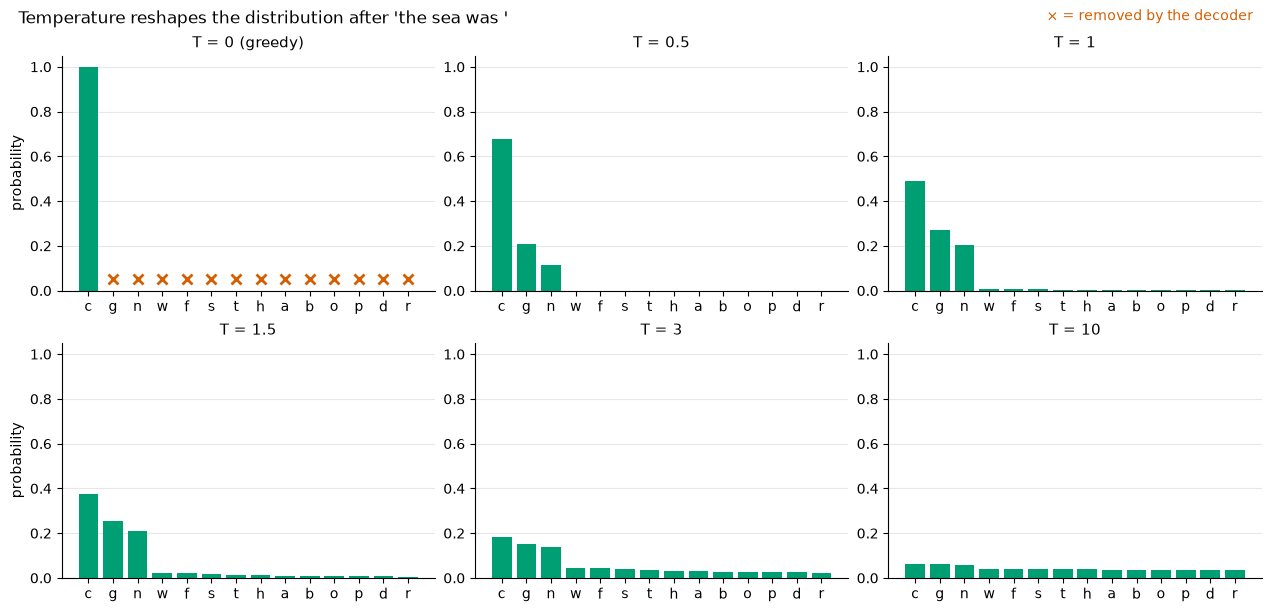

In [4]:
from src.analysis import entropy, temperature_sweep, top_tokens
from src.decoders import Decoder, make_generator
from src.model import default_char_lm, next_token_logits
from src.visualisation import (plot_entropy_vs_temperature, plot_metrics_vs,
                               plot_reshaped_distributions)

model = default_char_lm()
prompt = "the sea was "
logits = next_token_logits(model, prompt)
panel_temps = [0.0, 0.5, 1.0, 1.5, 3.0, 10.0]
warped = {f"T = {t:g}" + (" (greedy)" if t == 0 else ""): apply_temperature(logits, t)
          for t in panel_temps}
fig = plot_reshaped_distributions(model, logits, warped, n=14,
                                  title=f"Temperature reshapes the distribution after {prompt!r}")
save_figure(fig, "03_temperature_reshapes")
shown = top_tokens(model, logits, n=14)
save_json("03_temperature_reshapes", {
    "prompt": prompt,
    "tokens": shown["token"],
    "probabilities": {
        name: dict(zip(shown["token"], torch.softmax(w, dim=-1)[0, shown["token_id"]].tolist()))
        for name, w in warped.items()
    },
    "entropy_bits": {name: entropy(w, base=2).item() for name, w in warped.items()},
});

## 4. Entropy against temperature

Entropy (in bits) measures how spread out a distribution is: 0 for a certainty, log₂(vocabulary) for uniform.

In [5]:
sweep = temperature_sweep(logits, sorted({*S.decoding.temperatures, 7.5, 10.0, 20.0}))
sweep.round(3)

,temperature,entropy_bits,effective_choices,top1_prob
0,0.00,0.000,1.000,1.000
1,0.10,0.029,1.020,0.997
2,0.25,0.586,1.501,0.890
3,0.50,1.218,2.326,0.676
4,0.75,1.490,2.809,0.563
5,1.00,1.790,3.458,0.490
6,1.25,2.173,4.509,0.429
7,1.50,2.582,5.986,0.376
8,2.00,3.286,9.754,0.288
9,3.00,4.072,16.824,0.184


Entropy climbs monotonically from 0 (T = 0 is a point mass on the argmax) toward the uniform ceiling. `effective_choices` = 2^entropy reads as "how many equally likely characters is this like?"

## 5. Generate at every temperature

In [6]:
gen_prompt = "the keeper"
gen_ids = model.encode(gen_prompt)
texts = {}
for t in S.decoding.temperatures:
    out = Decoder.sampling(t).generate(model, gen_ids, 120, generator=make_generator(SEED))
    texts[f"{t:g}"] = model.decode(out[0, gen_ids.size(1):])
    print(f"T={t:<5g}{gen_prompt}{texts[f'{t:g}']!r}")
save_json("03_text_by_temperature", {"prompt": gen_prompt, "max_new_tokens": 120, "by_temperature": texts});

T=0    the keeper' climbed the stairs for the market was held on the days when his boat came out of the sea. in the morning and the small '
T=0.1  the keeper' climbed the stairs for the market was held on the days when his boat came out of the stairs for the last time. he lit t'
T=0.25 the keeper' saw him from the hills above the sea. in the morning and the small round loaves that came out of the lighthouse she gav'
T=0.5  the keeper' saw him from the hills above the sea. in the morning and the small round loaves that came out of the lighthouse stood a'
T=0.75 the keeper' saw him from the hills above the sea. every night the keeper climbed the stairs and lit the lamp and looked out over th'
T=1    the keeper' saw him from the hills above the sea. every night the keeper climbed the stairs and lit chim how the sun. the dog grew '
T=1.25 the keeper' saw him from the hills above the sea. every night the gulls laughed at the reepplis rooncom the sun. the dog sled the k'
T=1.5  the keeper' a

T=2    the keeper' en thees doa. the seais sofro.\ntaed enont the the red g\neone ove brabgurdec weopl oar ofcame hime.\nane of\nonee qus aid '
T=3    the keeper' en th erydia. thu seais, ang he came. whopddge. jveerrewdonedon is nigt.\nehre opllra lofcnme himetha shofrowes vellk ty'
T=5    the keeper' en jbyeaydoa.e mugjxlis nocgupwasynswjwnepddgg.ljsqende bonetoit fin gugmel e opllraryoncnmith, st,,abcof\nowes qdatk dy'


One seed, one prompt, one model. At the bottom of the range the same sentence loops; at the top the characters stop forming words. Now the same thing measured over every prompt and several seeds:

- **distinct-2**: are the word pairs varied? (repetition)
- **real-word rate**: what share of the generated words exist in the training corpus? (fluency)
- **fluent × varied** = real-word rate × distinct-2, high only if the text is both
- **single-answer accuracy**: on the fact prompts ("the capital of france is"), is the first word right?

In [7]:
from src.datasets import char_prompts
from src.evaluation import corpus_lexicon, run_arena

strategies = [Decoder.sampling(t) for t in S.decoding.temperatures]
arena = run_arena(model, char_prompts(), strategies, n_samples=S.generation.n_samples,
                  max_new_tokens=S.generation.max_new_tokens, seed=SEED,
                  lexicon=corpus_lexicon(), score_quality=False)
open_ = arena[arena["kind"] == "open"].groupby("decoder", observed=True)
single = arena[arena["kind"] == "single"].groupby("decoder", observed=True)
by_t = pd.DataFrame({
    "temperature": S.decoding.temperatures,
    "distinct_2": open_["distinct_2"].mean().to_numpy(),
    "valid_words": open_["valid_word_rate"].mean().to_numpy(),
    "single_accuracy": single["correct"].mean().astype(float).to_numpy(),
})
by_t["score"] = by_t["distinct_2"] * by_t["valid_words"]
by_t.round(3)

,temperature,distinct_2,valid_words,single_accuracy,score
0,0.00,0.364,0.987,1.000,0.359
1,0.10,0.612,0.993,1.000,0.608
2,0.25,0.817,0.992,1.000,0.810
3,0.50,0.878,0.988,1.000,0.868
4,0.75,0.906,0.974,1.000,0.882
5,1.00,0.911,0.908,1.000,0.827
6,1.25,0.946,0.725,0.967,0.686
7,1.50,0.961,0.585,0.600,0.562
8,2.00,0.998,0.293,0.200,0.292
9,3.00,1.000,0.120,0.000,0.120


usable band (fluent x varied within 10% of the best): T in [0.25, 1]


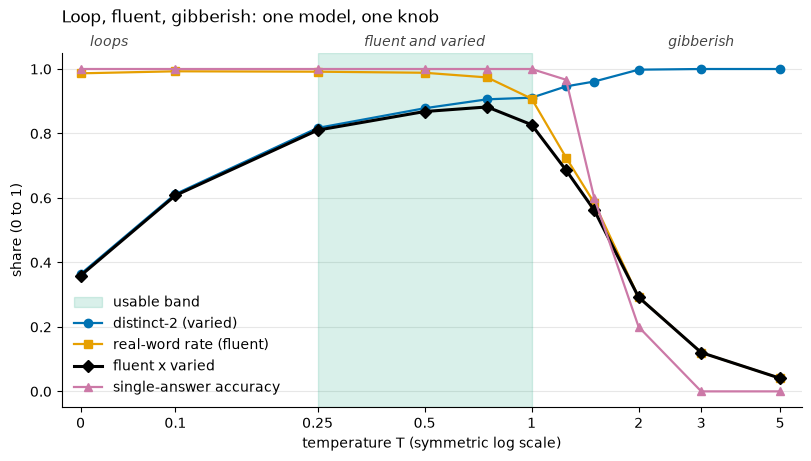

In [8]:
best = by_t["score"].max()
usable = by_t.loc[by_t["score"] >= 0.9 * best, "temperature"]
band = (float(usable.min()), float(usable.max()))
print(f"usable band (fluent x varied within 10% of the best): T in [{band[0]:g}, {band[1]:g}]")
fig = plot_metrics_vs(
    by_t, "temperature",
    {"distinct_2": "distinct-2 (varied)", "valid_words": "real-word rate (fluent)",
     "score": "fluent x varied", "single_accuracy": "single-answer accuracy"},
    xlabel="temperature T (symmetric log scale)", ylabel="share (0 to 1)", band=band,
    title="Loop, fluent, gibberish: one model, one knob", logx=True,
    regions={"loops": 0.03, "fluent and varied": 0.5, "gibberish": 3.0},
)
save_figure(fig, "03_temperature_sweep_metrics")
save_json("03_temperature_sweep_metrics", {
    "n_samples": S.generation.n_samples, "max_new_tokens": S.generation.max_new_tokens,
    "band_rule": "fluent x varied within 10% of the best", "usable_band": band,
    "by_temperature": by_t,
    "samples": arena[["prompt", "kind", "decoder", "sample", "completion", "correct"]],
});

## 6. The map

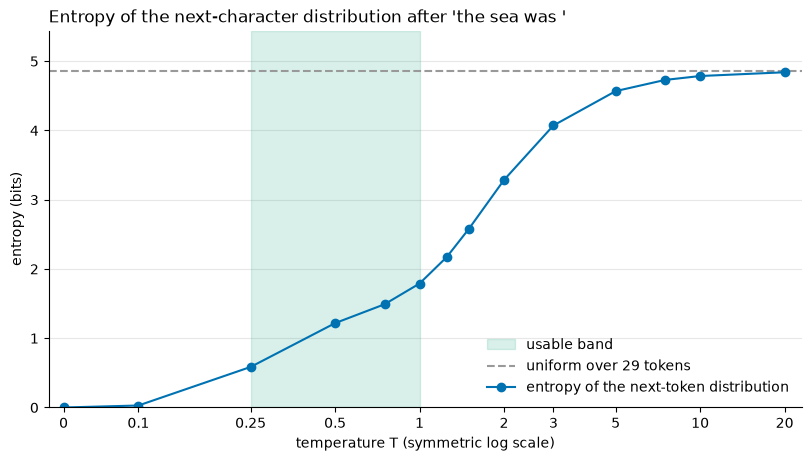

In [9]:
fig = plot_entropy_vs_temperature(
    sweep, model.vocab_size, band=band,
    title=f"Entropy of the next-character distribution after {prompt!r}",
)
save_figure(fig, "03_entropy_vs_temperature")
save_json("03_entropy_vs_temperature", {
    "prompt": prompt, "vocab_size": model.vocab_size, "usable_band": band, "sweep": sweep,
});

Left of the band, entropy is near zero: the sampler is effectively greedy and inherits greedy's loops. Right of it, entropy approaches the uniform ceiling: every character is nearly as likely as any other, so the output is noise. The usable band is where the distribution keeps its shape without collapsing to a point.

Note what the single-answer curve does: accuracy is perfect at low temperature and falls as T rises. The band that is best for open-ended text is already costing accuracy on facts. That tension is the subject of notebooks 05 and 06.

## 7. The limits, checked

In [10]:
cold = Decoder.sampling(1e-4).generate(model, gen_ids, 200, generator=make_generator(SEED))
cold_is_greedy = torch.equal(cold, Decoder.greedy().generate(model, gen_ids, 200))
hot = torch.softmax(apply_temperature(logits, 1e6), dim=-1)
max_gap_from_uniform = (hot - 1 / model.vocab_size).abs().max().item()
assert cold_is_greedy, "T -> 0 should be greedy"
assert max_gap_from_uniform < 1e-6, "T -> inf should be uniform"
save_json("03_limits", {"T=1e-4 generation equals greedy (200 chars)": cold_is_greedy,
                        "T=1e6 max |p - 1/V|": max_gap_from_uniform})
print("T -> 0 reproduces greedy token for token; "
      f"T -> inf is uniform to {max_gap_from_uniform:.1e}.")
print("Both are also asserted in tests/test_temperature.py.")

T -> 0 reproduces greedy token for token; T -> inf is uniform to 2.3e-07.
Both are also asserted in tests/test_temperature.py.


## 8. A real model at four temperatures

In [11]:
from huggingface_hub.utils import logging as hub_logging
from transformers.utils import logging as hf_logging

from src.model import load_model

hf_logging.set_verbosity_error()
hf_logging.disable_progress_bar()
hub_logging.set_verbosity_error()
hf = load_model("hf")  # distilgpt2: ~350 MB on first use, cached afterwards

In [12]:
hf_prompt = "Once upon a time, in a small village by the sea,"
hf_ids = hf.encode(hf_prompt)
hf_first_step = next_token_logits(hf, hf_prompt)
hf_rows = []
for t in [0.0, 0.7, 1.2, 2.5]:
    out = Decoder.sampling(t).generate(hf, hf_ids, 45, eos_token_id=hf.eos_token_id,
                                       generator=make_generator(SEED))
    text = hf.decode(out[0, hf_ids.size(1):])
    h = entropy(apply_temperature(hf_first_step, t), base=2).item()
    hf_rows.append({"temperature": t, "first_step_entropy_bits": h, "text": text})
    print(f"--- T = {t:g}  (first-step entropy {h:.1f} bits)")
    print(textwrap.fill(hf_prompt + text, 110), "\n")
save_json("03_distilgpt2_temperatures", {"model": hf.name, "prompt": hf_prompt,
                                         "max_new_tokens": 45, "results": hf_rows});

--- T = 0  (first-step entropy 0.0 bits)
Once upon a time, in a small village by the sea, a man, a woman, a man, a man, a man, a man, a man, a man, a
man, a man, a man, a man, a man, a man, a man, 



--- T = 0.7  (first-step entropy 3.2 bits)
Once upon a time, in a small village by the sea, a fairy could emerge, and in this case, they descended upon
the earth and took it to the sea. The Fairy was the most powerful of all, and its power and strength was made
manifest in the cauldron of a 



--- T = 1.2  (first-step entropy 10.0 bits)
Once upon a time, in a small village by the sea, Juno would first poison travellers. Intellectually, failed,
Juno cut low once again, we would spend farewells in actuars inside ACM Station and loneliness in several
bedroom diningrooms and libraries. We would find beauty 



--- T = 2.5  (first-step entropy 14.6 bits)
Once upon a time, in a small village by the sea, Juno fairy foyer furnace supplies closet dependenciesMoreover
abound Zurichdiocc La Gear Glad Inspective PublishingHot bacon outbreak Yamato fil)."Rev989 It AC 630 Thomas
Colomblees Sal Meielve Dal Griffin Park Alexandria cost cambpponet 



## What this bought you

- Temperature is `logits / T`. It never changes the ranking of tokens, only how far apart they are.
- T → 0 is greedy (and loops); T → ∞ is uniform (and rambles). Both limits hold exactly and are tested.
- Entropy rises monotonically with T. The usable band sits between "collapsed" and "uniform", and a sweep with objective metrics locates it for a given model.
- High temperature fails because it gives real probability to the long tail of absurd tokens. Cutting that tail is the next notebook: [04 · Top-k and nucleus](04_top_k_and_nucleus.ipynb).